# NLRB union elections — exploratory data analysis

Loads the `analytical_elections` view (RC/RM filings) and profiles the two
modeling targets: the regression target `vote_ratio` and the classification
target `success`.

In [ ]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

with duckdb.connect("./data/union_elections.duckdb", read_only=True) as con:
    df = con.execute("SELECT * FROM analytical_elections").fetchdf()
print(df.columns)
print(df.shape)
df.head()

Index(['case_number', 'case_type', 'city', 'state', 'date_filed',
       'date_closed', 'reason_closed', 'election_id', 'tally_type',
       'unit_size', 'election_date', 'more_than_one_election',
       'votes_for_union', 'votes_against', 'rpt_id', 'yr_covered',
       'pd_covered_from', 'pd_covered_to', 'f_num', 'desig_num', 'terminate',
       'representational', 'political', 'contributions', 'general_overhead',
       'union_administration', 'employer_name', 'region_assigned',
       'filing_status', 'filing_number_of_eligible_voters',
       'number_of_voters_on_petition_or_charge', 'certified_representative',
       'ballot_type', 'voting_unit_id', 'finance_union_name',
       'finance_aff_abbr', 'members', 'form_type', 'ttl_receipts',
       'ttl_disbursements', 'election_union_name', 'union_participant',
       'union_participant_type', 'pred_union_name', 'pred_f_num',
       'pred_f_num_score', 'pred_is_union', 'pred_union_name_score',
       'pred_is_union_score'],
      dtyp

,case_number,case_type,city,state,date_filed,date_closed,reason_closed,election_id,tally_type,unit_size,...,ttl_disbursements,election_union_name,union_participant,union_participant_type,pred_union_name,pred_f_num,pred_f_num_score,pred_is_union,pred_union_name_score,pred_is_union_score
0,18-RC-017670,RC,Waterloo,IA,2009-11-24,2010-01-19,Certification of Results,22467,Initial,404,...,2553029,"UNITED AUTOMOBILE WORKERS, LOCAL 838","UNITED AUTOMOBILE WORKERS, LOCAL 838",Union,AUTO WORKERS AFL-CIO,2232,0.9913,1,0.9974,0.9683
1,06-RC-012714,RC,Duncansville,PA,2009-12-04,2010-01-20,Certific. of Representative,6038,Initial,9,...,2158902,INTERNATIONAL UNION OF PAINTERS AND ALLIED TRA...,INTERNATIONAL UNION OF PAINTERS AND ALLIED TRA...,Union,PAINTERS AFL-CIO,540940,0.9812,1,0.9937,0.9611
2,25-RC-010486,RC,Columbia City,IN,2010-01-05,2010-02-23,Certific. of Representative,17593,Initial,14,...,1142069,"TEAMSTERS LOCAL NO. 414, AFFILIATED WITH THE I...","TEAMSTERS LOCAL NO. 414, AFFILIATED WITH THE I...",Union,TEAMSTERS,17875,0.9928,1,0.9982,0.9769
3,29-RC-011841,RC,Brooklyn,NY,2009-12-22,2010-01-29,Certification of Results,19213,Initial,79,...,41643,Grandpa Bus Company,Grandpa Bus Company,Union,"UNITED SERVICE WORKERS UNION, IUJAT",517592,0.0304,0,0.0870,0.0021
4,19-RC-015325,RC,Seattle,WA,2010-06-22,2010-08-06,Certific. of Representative,13649,Initial,12,...,9848442,INTERNATIONAL BROTHERHOOD OF TEAMSTERS LOCAL U...,INTERNATIONAL BROTHERHOOD OF TEAMSTERS LOCAL U...,Union,TEAMSTERS,5960,0.9956,1,0.9958,0.9402


## Case types, uniqueness

Confirming that the view is one row per election (one completed RC/RM case each).

In [4]:
print("rows:", len(df))
print("distinct filings:", df["case_number"].nunique())
print("distinct elections:", df["election_id"].nunique())
print()
df["case_type"].value_counts()

rows: 22196
distinct filings: 22196
distinct elections: 22196



case_type
RC    21598
RM      598
Name: count, dtype: int64

## Closing reason and the success label

An election is treated as successful when
`reason_closed == 'Certific. of Representative'`.

In [28]:
df["reason_closed"].value_counts(dropna=False)

reason_closed
Certific. of Representative    15170
Certification of Results        6615
Withdrawal Non-adjusted          339
Dismissal Non-adjusted            32
Withdrawal Adjusted               28
Administrative Closing             4
Amended Certification              4
Compliance w/BO                    2
Unit Clarification                 1
Dismissal Adjusted                 1
Name: count, dtype: int64

In [5]:
df["success"] = (
    df["reason_closed"]
    .map(lambda value: pd.NA if pd.isna(value) else int(value == "Certific. of Representative"))
    .astype("Int64")
)
print(df["success"].value_counts(dropna=False))

print(f'The fraction of rows that are success is {sum(df["success"]) / len(df)}')

success
1    15170
0     7026
Name: count, dtype: Int64
The fraction of rows that are success is 0.6834564786448009


Relatively mild class imbalance since there are still ~7000 cases that did not succeed.

## Target Variable: Vote net margin

`net_margin= votes_for_union - votes_against / <total_votes_cast>`.

votes_against or votes_for = null mean 0 votes.


In [ ]:
votes = df[['votes_for_union', 'votes_against']].where(
    df[['votes_for_union', 'votes_against']].notna(), 0
)
votes['total'] = votes.apply(sum, axis=1)

votes['net_margin'] = (votes['votes_for_union'] - votes['votes_against']) / votes['total']

votes["net_margin"].describe()

count     22102.0
mean     0.361165
std      0.550494
min          -1.0
25%     -0.043478
50%      0.428571
75%      0.888889
max           1.0
Name: net_margin, dtype: Float64

Text(0, 0.5, '# of elections')

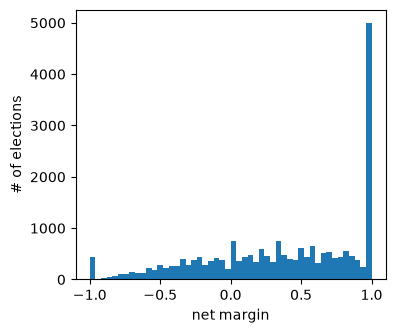

In [10]:
plt.figure(figsize=(4, 3.5))
plt.hist(votes['net_margin'], bins=50)
plt.xlabel('net margin')
plt.ylabel('# of elections')

## Missingness

In [7]:
df.isna().mean().sort_values(ascending=False).head(30)

certified_representative            0.538385
filing_number_of_eligible_voters    0.349207
desig_num                           0.281177
general_overhead                    0.252478
political                           0.252478
union_administration                0.252478
representational                    0.252478
votes_against                       0.225176
contributions                       0.168544
terminate                           0.155028
ttl_receipts                        0.135925
pd_covered_from                     0.135880
yr_covered                          0.135880
pd_covered_to                       0.135880
f_num                               0.135880
rpt_id                              0.135880
finance_aff_abbr                    0.135880
finance_union_name                  0.135880
form_type                           0.135880
ttl_disbursements                   0.135880
votes_for_union                     0.023473
pred_is_union                       0.018472
pred_union

## LM Report and Finances

In [8]:
(
    df.groupby("form_type", dropna=False)
        .agg(
            rows=("case_number", "size"),
            median_disbursements=("ttl_disbursements", "median"),
            median_receipts=("ttl_receipts", "median"),
        )
        .sort_values("rows", ascending=False)
)

,rows,median_disbursements,median_receipts
form_type,,,
LM-2,16592,5030522.5,5141985.0
NaN,3016,<NA>,<NA>
LM-3,1903,46689.0,56914.0
LM-4,685,500.0,872.0


### Union Size

In [19]:
unions = df.drop_duplicates(subset='f_num').dropna(subset='members')
unions['members'].describe()

count          2345.0
mean      4867.883156
std      26600.684407
min               0.0
25%             288.0
50%            1008.0
75%            2949.0
max          848323.0
Name: members, dtype: Float64

In [ ]:
# Largest unions. Different member numbers for same union because depending on the year of the LM report, has different number of members.

unions[unions['members']>1e5][['pred_union_name', 'members']].sort_values(by='members', ascending=False)

,pred_union_name,members
14124,TEACHERS AFL-CIO,848323
1699,TEACHERS AFL-CIO,663681
542,SERVICE EMPLOYEES,369933
1716,STATE COUNTY AND MUNI EMPLS AFL-CIO,228086
803,"SHEET METAL, AIR, RAIL AND TRANSPORTATION WORKERS",203280
1721,TEACHERS AFL-CIO,192518
780,SERVICE EMPLOYEES,188129
14979,TEAMSTERS,146464
1809,NATIONAL EDUCATION ASN IND,132940
11740,TEAMSTERS,113506


Text(0, 0.5, 'Number of unions ')

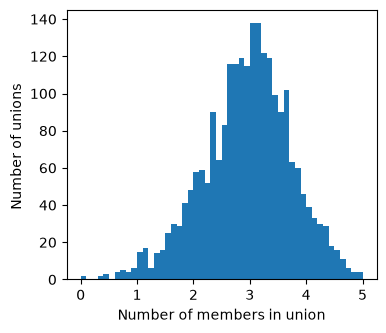

In [ ]:
# Distribution of union sizes for unique unions in the dataset

plt.figure(figsize=(4, 3.5))
plt.hist(unions['members'].apply(np.log10), bins=50, range=[0, 5])
plt.xlabel('Log 10 number of members in union')
plt.ylabel('Number of unions ')

Text(0, 0.5, 'Number of elections with union of that size')

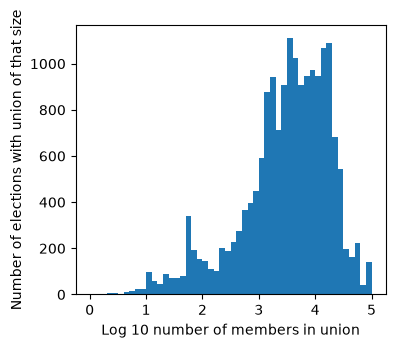

In [44]:
# Distribution of union sizes based on counts of unions by election.

plt.figure(figsize=(4, 3.5))
plt.hist(df['members'].apply(np.log10), bins=50, range=[0, 5])
plt.xlabel('Log 10 number of members in union')
plt.ylabel('Number of elections with union of that size')

Seems like elections tend to have larger unions as participants (larger as compared to distribution of unique unions in dataset)

**Make sure to use the log of the number of members as the feature**

### Union disbursements

Only forms LM2 report total disbursements by category of representational/political activities. Consider only these for now.

In [47]:
# How many rows have the right report type
df['form_type'].value_counts()

form_type
LM-2    16592
LM-3     1903
LM-4      685
Name: count, dtype: int64

Text(0.5, 0, 'Fraction of disbursements on union administration')

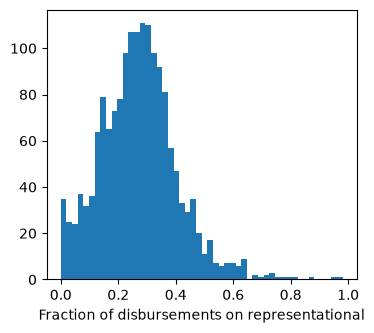

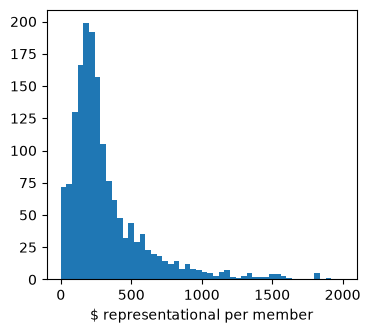

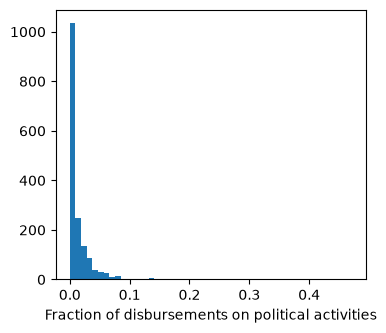

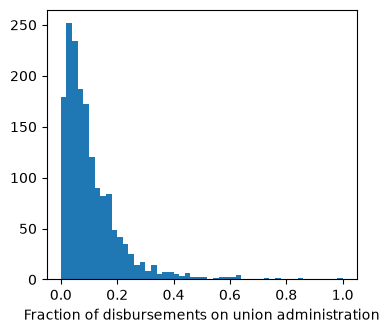

In [58]:
fin = unions.dropna(subset=['ttl_disbursements', 'representational', 'political', 'members'])

fin = fin.where(fin.notna(), 0)
fin['rep_frac'] = fin['representational'] / fin['ttl_disbursements']
fin['pol_frac'] = fin['political'] / fin['ttl_disbursements']
fin['admin_frac'] = fin['union_administration'] / fin['ttl_disbursements']
fin['rep_per_mem'] = fin['representational'] / fin['members']

plt.figure(figsize=(4, 3.5))
plt.hist(fin['rep_frac'], bins=50)
plt.xlabel('Fraction of disbursements on representational')
plt.figure(figsize=(4, 3.5))
plt.hist(fin['rep_per_mem'], bins=50, range=[0, 2e3])
plt.xlabel('$ representational per member')
plt.figure(figsize=(4, 3.5))
plt.hist(fin['pol_frac'], bins=50)
plt.xlabel('Fraction of disbursements on political activities')
plt.figure(figsize=(4, 3.5))
plt.hist(fin['admin_frac'], bins=50)
plt.xlabel('Fraction of disbursements on union administration')

## Success by case type and state

In [9]:
df.groupby("case_type")["success"].agg(["size", "mean"])

,size,mean
case_type,,
RC,21598,0.688721
RM,598,0.493311


In [11]:
bystate = (
  df.groupby("state")["success"]
    .agg(["size", "mean"])
    .sort_values("size", ascending=False)
)

print(bystate.head(15))

print(bystate.sort_values("mean", ascending=True).head(15))

       size      mean
state                
CA     3179  0.707455
NY     2397  0.727159
IL     1515   0.69571
PA     1398  0.658083
NJ     1042   0.65643
WA      999  0.714715
MI      781   0.62612
MA      776  0.734536
OH      732  0.560109
TX      695  0.689209
OR      612  0.668301
MN      555  0.540541
MD      533  0.739212
CT      484  0.702479
FL      482  0.738589
       size      mean
state                
SD       17  0.411765
IA      146  0.465753
ID       84  0.488095
WY       31  0.516129
AR       63  0.539683
MN      555  0.540541
OH      732  0.560109
MS       62  0.564516
IN      400      0.59
KY      252  0.599206
WI      265       0.6
WV      156  0.608974
MO      461  0.611714
CO      299   0.61204
VI       26  0.615385


## Notes

- Vote counts come from the `tally` table (`votes_for_union` /
  `votes_against`). Elections with a contested (>2 option) or only-"No union"
  tally are excluded.
- Elections with zero or missing votes against have an undefined ratio, so
  they are dropped for regression.
- `training.py` loads the same view, collapses it to one row per election, and
  builds the feature/target frames.